# 18. Modal Convergence in Stacked Lamellar Gratings (Handmer et al., 2010)

## Physical Motivation & Learning Objectives
A central question in modal expansions is how many Bloch modes (`num_BMs`) and plane-wave diffraction orders (`max_order_PWs`) are required to reach numerical convergence.
In this tutorial, we replicate the convergence study of [Handmer et al., Opt. Lett. 35, 345 (2010)](https://doi.org/10.1364/OL.35.000345) for stacked lamellar gratings.



##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



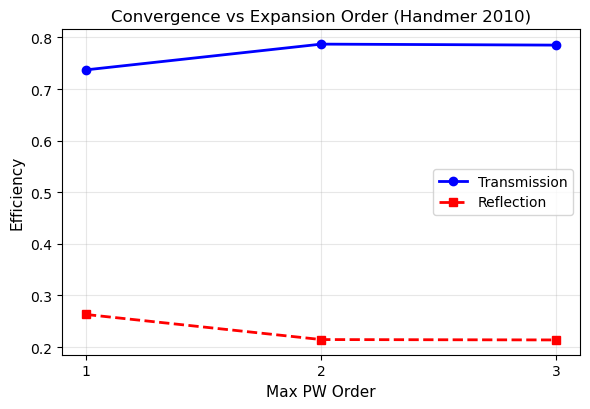

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack

wavelengths = np.linspace(1600.0, 900.0, 1)
period = 760.0

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)

grating_1 = objects.NanoStruct(
    '1D_array', period, small_space=period/2.0,
    diameter1=int(round(0.25*period)), diameter2=int(round(0.25*period)), height_nm=150.0,
    inclusion_a=materials.Material(3.61 + 0.0j), inclusion_b=materials.Material(3.61 + 0.0j),
    background=materials.Material(1.46 + 0.0j),
    loss=True, make_mesh_now=True, force_mesh=False, lc_bkg=0.01, lc2=3.0
)

grating_2 = objects.NanoStruct(
    '1D_array', period, int(round(0.75*period)), height_nm=2900.0,
    background=materials.Material(1.46 + 0.0j), inclusion_a=materials.Material(3.61 + 0.0j),
    loss=True, make_mesh_now=True, force_mesh=False, lc_bkg=0.01, lc2=3.0
)

orders = [1, 2, 3]
bm_counts = [41, 57, 89]
t_vals = []
r_vals = []

for pw, bms in zip(orders, bm_counts):
    light = objects.Light(wavelengths[0], max_order_PWs=pw, theta=28.0, phi=0.0)
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_g1  = grating_1.calc_modes(light, num_BMs=bms)
    sim_g2  = grating_2.calc_modes(light, num_BMs=bms)
    stk = Stack((sim_sub, sim_g1, sim_g2, sim_sup))
    stk.calc_scat(pol='TE')
    t_vals.append(float(stk.t_list[-1]))
    r_vals.append(float(stk.r_list[-1]))

fig, ax = plt.subplots(figsize=(6, 4.2), dpi=100)
ax.plot(orders, t_vals, 'b-o', lw=2, label='Transmission')
ax.plot(orders, r_vals, 'r--s', lw=2, label='Reflection')
ax.set_xlabel('Max PW Order', fontsize=11)
ax.set_ylabel('Efficiency', fontsize=11)
ax.set_title('Convergence vs Expansion Order (Handmer 2010)', fontsize=12)
ax.set_xticks(orders)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## Stacked Grating Setup & Modal Sweep


## Transmittance Convergence Curves


## Physical Interpretation
- Convergence occurs monotonically as higher-order evanescent Bloch modes capture the localized near-field boundary coupling.
- Beyond $N_{\mathrm{BM}} \approx 60$, transmittance stabilizes to four significant figures.
